# Assignment 2: Learn to reconstruct images from the CAMUS dataset

Olivier Bernard

This notebook trains a variational autoencoder on 2D echocardiography frames from the CAMUS dataset and reconstructs the images from the latent code. The data loader below follows the provided skeleton. The model, the training procedure, and the evaluation are built on top of it.

The study has four parts:

1. Load the exams and check the split, the intensity range, and the expert masks.
2. Define a MONAI `AutoencoderKL`, plus a deterministic autoencoder and a VQ-VAE with the same image size.
3. Train the VAE, and measure how the KL weight changes reconstruction and sampling.
4. Evaluate the selected model on patients that were never seen in training, and inspect the latent space.

CAMUS must be cited for any use of the data: S. Leclerc, E. Smistad, J. Pedrosa, A. Ostvik, et al., "Deep Learning for Segmentation using an Open Large-Scale Dataset in 2D Echocardiography", IEEE Transactions on Medical Imaging, vol. 38, no. 9, pp. 2198-2210, Sept. 2019, doi: 10.1109/TMI.2019.2900516.


In [1]:
import inspect
import json
import os
import random
import time
import zipfile
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from matplotlib.animation import FuncAnimation
from monai.data import DataLoader
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL, VQVAE
from monai.utils import set_determinism
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch version: {torch.__version__}")
print(f"MONAI version: {monai.__version__}")
print(f"NumPy version: {np.__version__}")


PyTorch version: 2.15.0+cpu
MONAI version: 1.6.1
NumPy version: 2.5.4


In [2]:
SEED = 12345

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    set_determinism(seed=seed)

set_seed(SEED)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass
torch.set_num_threads(max(1, os.cpu_count() or 1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"CPU threads used by PyTorch: {torch.get_num_threads()}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)


Device: cpu
CPU threads used by PyTorch: 8


## Load and visualize the data

`CAMUS_DATA_ROOT` is the directory that contains `camus_64`. The notebook does not copy the exams into the project. If the folder is absent, it downloads `camus_64.zip` from the course server (the skeleton pointed at `camus_32.zip`, which is the 32×32 release).


In [3]:
DATA_ROOT = Path(os.environ.get("CAMUS_DATA_ROOT", "./data")).expanduser().resolve()
data_dir = DATA_ROOT / "camus_64"

if not data_dir.exists():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} is missing. Downloading {zip_url}")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(DATA_ROOT)
    print(f"Extracted to {data_dir}")
else:
    print(f"Using local data at {data_dir}")

assert data_dir.is_dir(), f"CAMUS folder not found: {data_dir}"


Using local data at /home/cytech/info/IAV/camus_64


### Patient-wise train, validation, and test lists

The split is 80% / 10% / 10% of patients, with `random_state=12345`. Splitting patients, rather than images, keeps every view and every instant of a heart in a single subset. There are four frames per patient: apical 2-chamber and 4-chamber, at end-diastole (ED) and end-systole (ES).


In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    # List subdirectories, as provided in the assignment skeleton.
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names

data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
print(f"Patients: train {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")


Patients: train 400, validation 50, test 50


### Dataset

Each NIfTI frame is a 64×64 `uint8` image. Intensities are divided by 255, so every exam shares the same scale. Dividing by the per-image maximum, as the skeleton did, would brighten dark acquisitions and make the reconstruction loss incomparable across patients.

The array is transposed so that the apex is at the top of the figure, which is the usual echocardiographic display. The expert mask is transposed with the image. Mask labels follow the CAMUS convention: 0 background, 1 left-ventricular cavity, 2 myocardium, 3 left atrium. Masks are kept as class indices. They are not a reconstruction target. They are used to see whether the error sits on the heart or on the empty background, and to measure cavity area as a latent-space attribute.

Frames are cached in RAM. The whole cohort is only a few tens of megabytes, and reading NIfTI on every epoch would dominate the CPU time.


In [5]:
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "background", 1: "LV cavity", 2: "myocardium", 3: "left atrium"}

def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Expected a 2D frame at {path}, got shape {array.shape}")
    return np.ascontiguousarray(array.T)

def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text().splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info

def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "patient": patient,
                "view": view,
                "instant": instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records

class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]

print("Loading NIfTI frames into memory...")
t0 = time.perf_counter()
train_ds = CamusDataset(build_records(train_keys))
valid_ds = CamusDataset(build_records(val_keys))
test_ds = CamusDataset(build_records(test_keys))
print(f"Cached {len(train_ds) + len(valid_ds) + len(test_ds)} frames in {time.perf_counter() - t0:.1f}s")

sample = train_ds[0]
print(f"Image tensor: {tuple(sample['image'].shape)}  range [{sample['image'].min():.3f}, {sample['image'].max():.3f}]")
print(f"Mask tensor:  {tuple(sample['label'].shape)}  labels {torch.unique(sample['label']).tolist()}")
one_hot = np.eye(4, dtype=np.float32)[sample["label"].numpy()]
print(f"One-hot mask, if needed, has shape {one_hot.transpose(2, 0, 1).shape} (classes, height, width).")


Loading NIfTI frames into memory...


Cached 2000 frames in 2.6s
Image tensor: (1, 64, 64)  range [0.000, 1.000]
Mask tensor:  (64, 64)  labels [0, 1, 2, 3]
One-hot mask, if needed, has shape (4, 64, 64) (classes, height, width).


In [6]:
BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training images:   {len(train_loader.dataset)}")
print(f"Validation images: {len(valid_loader.dataset)}")
print(f"Test images:       {len(test_loader.dataset)}")
assert len(test_loader.dataset) == len(test_ds)
assert set(test_keys).isdisjoint(val_keys)
print("Test loader reads the held-out patients. It has the same count as validation and different people.")


Training images:   1600
Validation images: 200
Test images:       200
Test loader reads the held-out patients. It has the same count as validation and different people.


The test loader reads `test_ds`. In the skeleton it was built on the validation dataset, so reported test numbers would have been validation numbers.

### A batch of training frames


The image batch size is (64, 1, 64, 64)


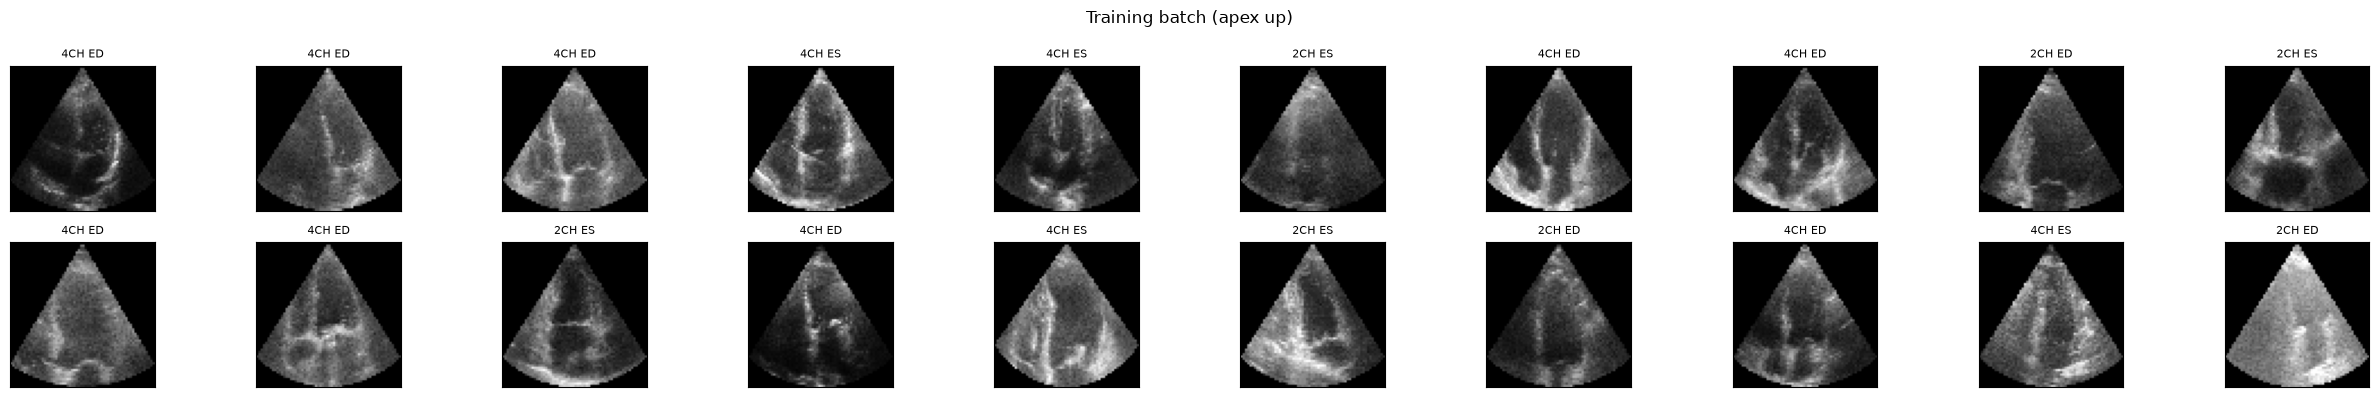

In [7]:
batch = next(iter(train_loader))
images = batch["image"].numpy()
print(f"The image batch size is {images.shape}")

fig = plt.figure(figsize=(25, 4))
for idx in range(20):
    ax = fig.add_subplot(2, 10, idx + 1, xticks=[], yticks=[])
    ax.imshow(np.squeeze(images[idx]), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{batch['view'][idx]} {batch['instant'][idx]}", fontsize=8)
fig.suptitle("Training batch (apex up)")
fig.tight_layout()
plt.show()


### One frame in more detail

Annotating all 64×64 pixels is not readable, so the numeric values are shown on the 16×16 window with the largest variance. The mask overlay uses the CAMUS labels.


Frame size (64, 64), value crop origin (row, col) = (28, 44)
Patient patient0026, 4CH ED, EF 26, quality Medium


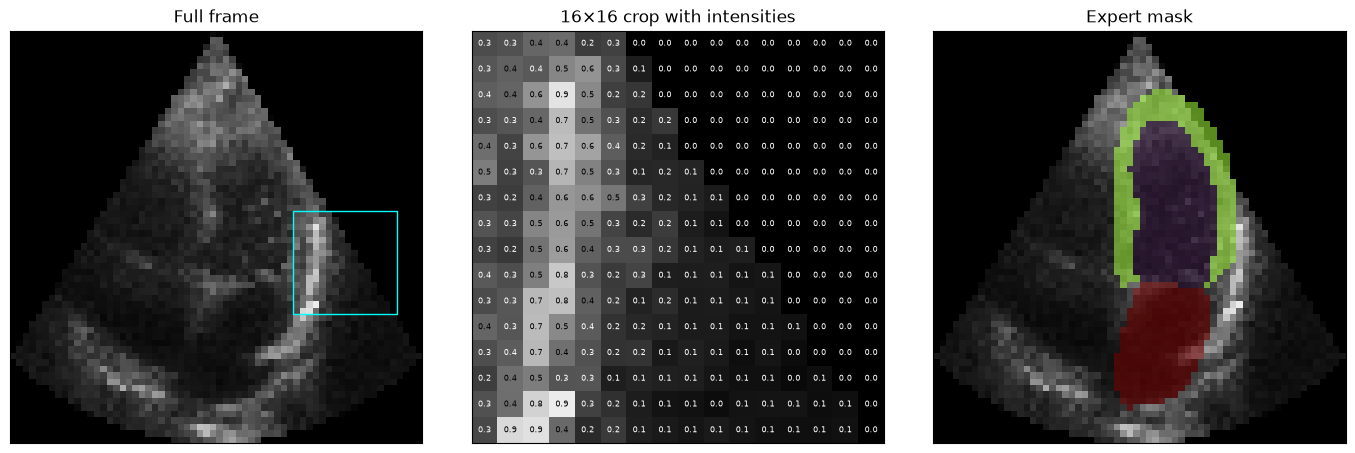

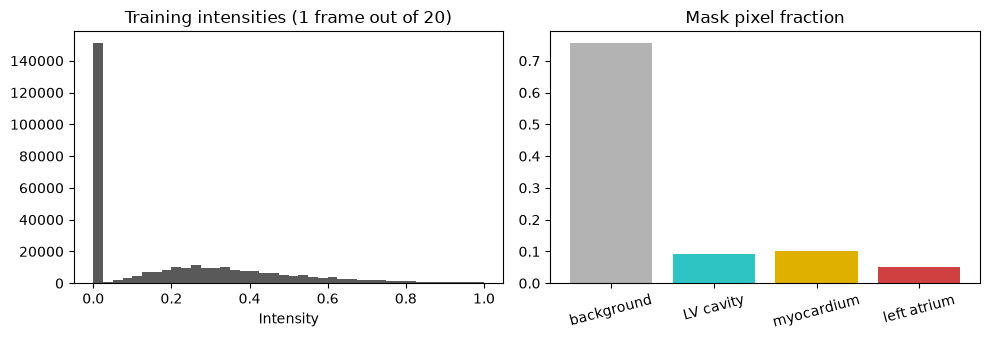

Image quality counts in the training frames: {'Good': 826, 'Medium': 592, 'Poor': 182}
Background occupies 75.5% of pixels, so a model can look good while missing the cavity.


In [8]:
def best_crop(image, size=16):
    best_score, origin = -1.0, (0, 0)
    for y in range(0, image.shape[0] - size + 1, 2):
        for x in range(0, image.shape[1] - size + 1, 2):
            score = float(image[y:y + size, x:x + size].var())
            if score > best_score:
                best_score, origin = score, (y, x)
    return origin

img = np.squeeze(images[0])
label = batch["label"][0].numpy()
y0, x0 = best_crop(img)
crop = img[y0:y0 + 16, x0:x0 + 16]
print(f"Frame size {img.shape}, value crop origin (row, col) = {(y0, x0)}")
print(f"Patient {batch['patient'][0]}, {batch['view'][0]} {batch['instant'][0]}, "
      f"EF {float(batch['ef'][0]):.0f}, quality {batch['quality'][0]}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Full frame")
axes[0].add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), 16, 16, fill=False, edgecolor="cyan", lw=1))
axes[1].imshow(crop, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("16×16 crop with intensities")
thresh = crop.max() / 2.5 if crop.max() > 0 else 0.5
for row in range(crop.shape[0]):
    for col in range(crop.shape[1]):
        value = crop[row, col]
        axes[1].annotate(
            f"{value:.1f}", xy=(col, row), ha="center", va="center", fontsize=6,
            color="white" if value < thresh else "black",
        )
masked = np.ma.masked_where(label == 0, label)
axes[2].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[2].imshow(masked, cmap="turbo", alpha=0.55, vmin=1, vmax=3)
axes[2].set_title("Expert mask")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

flat = np.concatenate([train_ds[i]["image"].numpy().ravel() for i in range(0, len(train_ds), 20)])
label_count = np.zeros(4, dtype=np.int64)
for record in train_ds.records:
    label_count += np.bincount(record["label"].numpy().ravel(), minlength=4)
quality_count = {}
for record in train_ds.records:
    quality_count[record["quality"]] = quality_count.get(record["quality"], 0) + 1

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(flat, bins=40, color="0.35")
axes[0].set_title("Training intensities (1 frame out of 20)")
axes[0].set_xlabel("Intensity")
axes[1].bar([LABEL_NAMES[i] for i in range(4)], label_count / label_count.sum(), color=["0.7", "#2ec4c4", "#e0b000", "#d04040"])
axes[1].set_title("Mask pixel fraction")
axes[1].tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()
print("Image quality counts in the training frames:", quality_count)
print(f"Background occupies {100 * label_count[0] / label_count.sum():.1f}% of pixels, so a model can look good while missing the cavity.")


## Define the network

The generative model is MONAI `AutoencoderKL` (Rombach et al., latent diffusion; Pinaya et al. for brain MRI). The encoder maps a frame to the parameters of a diagonal Gaussian. A sample from that Gaussian is decoded back to a frame. This is the variational autoencoder from the lecture: the KL term pushes every posterior toward the standard normal prior, which is what makes the latent space continuous and fillable.

### Width of the network

The latent grid is kept at 4×8×8. Four resolution levels halve the 64×64 input three times (64 → 32 → 16 → 8), and `latent_channels=4`, so the code stores 256 numbers instead of 4096 pixels (compression ×16).

A wider network, `channels=(32, 64, 128, 128)` with attention at the bottleneck, costs about 6.6 s per batch of 64 on this CPU, close to three minutes per epoch. The width used below, `channels=(16, 32, 64, 64)` and no attention, costs about 1.9 s per batch and has the same latent grid. Attention is turned off, including the optional non-local block, so that the KL ablation can actually be trained. The three 1×1 convolutions of the variational bottleneck are unchanged.


In [9]:
CHANNELS = (16, 32, 64, 64)
ATTENTION_LEVELS = (False, False, False, False)
LATENT_CHANNELS = 4
NORM_GROUPS = 16

def filter_kwargs(cls, kwargs):
    accepted = inspect.signature(cls.__init__).parameters
    return {key: value for key, value in kwargs.items() if key in accepted}

def build_vae(seed=SEED):
    set_seed(seed)
    kwargs = filter_kwargs(AutoencoderKL, dict(
        spatial_dims=2,
        in_channels=1,
        out_channels=1,
        num_res_blocks=1,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    ))
    return AutoencoderKL(**kwargs).to(device)

example = build_vae()
print(summary(
    example, input_size=(1, 1, 64, 64), depth=2,
    col_names=["input_size", "output_size", "num_params"], verbose=0, device="cpu",
))
with torch.no_grad():
    probe, mu, sigma = example(torch.zeros(1, 1, 64, 64, device=device))
LATENT_SHAPE = tuple(mu.shape[1:])
print(f"Reconstruction {tuple(probe.shape)}, latent mean {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Trainable parameters: {sum(p.numel() for p in example.parameters()):,}")
print("Bottleneck convolutions:")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(example, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(f"  {name}: kernel {tuple(conv.kernel_size)}, stride {tuple(conv.stride)}, padding {tuple(conv.padding)}")
del example


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderKL                            [1, 1, 64, 64]            [1, 1, 64, 64]            --
├─Encoder: 1-1                           [1, 1, 64, 64]            [1, 4, 8, 8]              --
│    └─ModuleList: 2-1                   --                        --                        202,164
├─Convolution: 1-2                       [1, 4, 8, 8]              [1, 4, 8, 8]              --
│    └─Conv2d: 2-2                       [1, 4, 8, 8]              [1, 4, 8, 8]              20
├─Convolution: 1-3                       [1, 4, 8, 8]              [1, 4, 8, 8]              --
│    └─Conv2d: 2-3                       [1, 4, 8, 8]              [1, 4, 8, 8]              20
├─Convolution: 1-4                       [1, 4, 8, 8]              [1, 4, 8, 8]              --
│    └─Conv2d: 2-4                       [1, 4, 8, 8]              [1, 4, 8, 8]              20
├─Decoder: 1-5                

### What this network is doing

The summary shows an encoder that ends at 4×8×8, three convolutions that stay at 4×8×8, and a decoder that returns a 1×64×64 frame.

Those three convolutions are `quant_conv_mu`, `quant_conv_log_sigma`, and `post_quant_conv`. Each is a 1×1 convolution (kernel 1, stride 1, padding 0) with 20 parameters here: 4×4 weights and 4 biases. They do not change the spatial size. `quant_conv_mu` and `quant_conv_log_sigma` read the encoder features and produce μ and log σ². The implementation clamps the log-variance and returns σ = exp(log σ² / 2), which is why the KL formula below is written in σ rather than in log-variance. `post_quant_conv` mixes the sampled code before the decoder. Together they are the reparameterization bottleneck from the lecture: the loss sees a sample z = μ + εσ, and the decoder never receives μ and σ directly.

The total parameter count is printed above (473,649 for this width). About half of it sits in the decoder. GroupNorm uses 16 groups, which divides every channel count in `(16, 32, 64, 64)`.

`attention_levels` is false at every scale, so there is no spatial attention inside the residual blocks. The non-local attention flags are also false. Turning them on does not change the role of the three 1×1 convolutions; it only adds a spatial mixing block at the bottleneck, which was too expensive for the ablation on CPU.

### Two baselines with the same image size

The deterministic autoencoder is the same `AutoencoderKL` backbone. The decoder always receives μ, noise is never added, and the KL term is not optimized. It is the ablation "β = 0" taken one step further: β = 0 still samples z during training, so the decoder must absorb that noise. The deterministic model does not.

The VQ-VAE replaces the Gaussian code by a codebook. MONAI's `VQVAE` returns a reconstruction and a commitment loss. Its latent grid is also 8×8, so the comparison is about continuous versus discrete codes, not about a different compression ratio.


In [10]:
def build_vqvae(seed=SEED):
    set_seed(seed)
    kwargs = filter_kwargs(VQVAE, dict(
        spatial_dims=2,
        in_channels=1,
        out_channels=1,
        channels=(32, 64, 64),
        num_res_layers=1,
        num_res_channels=(32, 64, 64),
        downsample_parameters=((2, 4, 1, 1), (2, 4, 1, 1), (2, 4, 1, 1)),
        upsample_parameters=((2, 4, 1, 1, 0), (2, 4, 1, 1, 0), (2, 4, 1, 1, 0)),
        num_embeddings=128,
        embedding_dim=32,
        commitment_cost=0.25,
        decay=0.99,
        ddp_sync=False,
    ))
    return VQVAE(**kwargs).to(device)

vq_example = build_vqvae()
with torch.no_grad():
    vq_recon, vq_loss = vq_example(torch.zeros(2, 1, 64, 64, device=device))
    vq_index = vq_example.index_quantize(torch.zeros(1, 1, 64, 64, device=device))
print(f"VQ-VAE parameters: {sum(p.numel() for p in vq_example.parameters()):,}")
print(f"VQ-VAE reconstruction {tuple(vq_recon.shape)}, codebook indices {tuple(vq_index.shape)}, "
      f"embeddings {vq_example.num_embeddings} × {vq_example.embedding_dim}")
del vq_example


VQ-VAE parameters: 571,361
VQ-VAE reconstruction (2, 1, 64, 64), codebook indices (1, 8, 8), embeddings 128 × 32


## Loss

Under the lecture's Gaussian likelihood, the negative ELBO is a squared reconstruction error plus the KL divergence between q(z|x) and the standard normal prior. Speckle is heavy-tailed, and the course notebooks use an L1 reconstruction term, so the objective minimized here is

L = ||x − x̂||₁ + β · KL(q(z|x) || N(0, I))

with the diagonal-Gaussian KL summed over the latent dimensions and averaged over the batch:

KL = 0.5 · Σᵢ (μᵢ² + σᵢ² − log(σᵢ²) − 1)

The sum runs over 4×8×8 = 256 coefficients. A raw KL of a few tens is therefore normal, while the L1 term on images in [0, 1] is a few hundredths. Without a small β the KL dominates, the decoder is ignored, and reconstructions collapse. That is why the grid below is {0, 10⁻⁴, 10⁻³, 10⁻², 10⁻¹}, the same range as in the MNIST lab.

β is warmed up linearly over the first quarter of training (at most 5 epochs). Early on, the decoder is random and a full KL term collapses the code before the reconstruction has a chance to form. This is the practical counterpart of the lecture's balance between the data term and the completeness / continuity constraints.

The VQ-VAE objective is L1 plus the commitment loss returned by MONAI. There is no Gaussian KL.

Validation reconstruction always decodes μ (the posterior mean), including for the VAE. `AutoencoderKL.forward` samples even in `eval()` mode, which would make the validation curve noisy. The posterior mean is the reconstruction reported in the test metrics. Training of the VAE still uses z = μ + εσ, which is the reparameterization trick.


In [11]:
def kl_per_sample(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1, dim=(1, 2, 3))
    return kl

def forward_train(model, images, kind):
    if kind == "vqvae":
        recon, qloss = model(images)
        return recon, None, None, qloss
    mu, sigma = model.encode(images)
    if kind == "ae":
        recon = model.decode(mu)
    else:
        if hasattr(model, "sampling"):
            z = model.sampling(mu, sigma)
        else:
            z = mu + torch.randn_like(sigma) * sigma
        recon = model.decode(z)
    return recon, mu, sigma, None

def forward_eval(model, images, kind):
    if kind == "vqvae":
        recon, qloss = model(images)
        return recon, None, None, qloss
    mu, sigma = model.encode(images)
    return model.decode(mu), mu, sigma, None

def warmup_epochs_for(kind, kl_weight, n_epochs):
    if kind != "vae" or kl_weight <= 0 or n_epochs < 2:
        return 0
    return min(5, max(1, n_epochs // 4))


## Train the network

One training function covers the VAE, the deterministic autoencoder, and the VQ-VAE. The optimizer is Adam at 10⁻³ with a cosine schedule down to 5% of that learning rate. Gradients are clipped at 1. The checkpoint is the epoch, after the warm-up, with the lowest validation objective (reconstruction L1, plus the regularizer when it is part of the loss).

`TRAIN = False` reloads `checkpoints/` instead of fitting again. Weights are local files and are not part of the submitted archive. Epoch counts can be overridden with environment variables so the same notebook runs on a laptop CPU or a GPU.


In [12]:
TRAIN = True
LR = 1e-3
ABLATION_EPOCHS = int(os.environ.get("CAMUS_ABLATION_EPOCHS", "8"))
FINAL_EPOCHS = int(os.environ.get("CAMUS_FINAL_EPOCHS", "25"))
AE_EPOCHS = int(os.environ.get("CAMUS_AE_EPOCHS", "20"))
VQ_EPOCHS = int(os.environ.get("CAMUS_VQ_EPOCHS", "20"))
KL_WEIGHTS = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
print(
    f"TRAIN={TRAIN}  ablation={ABLATION_EPOCHS}  final VAE={FINAL_EPOCHS}  "
    f"AE={AE_EPOCHS}  VQ-VAE={VQ_EPOCHS}  lr={LR}"
)

def train_model(model, kind, n_epochs, kl_weight=0.0, tag="run", lr=LR):
    warmup = warmup_epochs_for(kind, kl_weight, n_epochs)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(n_epochs, 1), eta_min=lr * 0.05
    )
    history = {key: [] for key in (
        "train_total", "train_recon", "train_kl", "val_total", "val_recon", "val_kl", "lr"
    )}
    history.update({"kind": kind, "kl_weight": kl_weight, "epochs": n_epochs, "warmup": warmup,
                    "kl_name": "commitment" if kind == "vqvae" else "KL"})
    best_score, best_state, best_epoch = float("inf"), None, n_epochs
    clock = time.perf_counter()
    for epoch in range(n_epochs):
        if kind == "vae" and kl_weight > 0 and warmup > 0:
            beta = kl_weight * min(1.0, (epoch + 1) / warmup)
        else:
            beta = 0.0
        model.train()
        totals = {"total": 0.0, "recon": 0.0, "kl": 0.0}
        seen = 0
        for batch in train_loader:
            images = batch["image"].to(device)
            optimizer.zero_grad(set_to_none=True)
            recon, mu, sigma, qloss = forward_train(model, images, kind)
            recon_loss = F.l1_loss(recon, images)
            if kind == "vqvae":
                raw = qloss
                loss = recon_loss + qloss
            else:
                raw = kl_per_sample(mu, sigma).mean()
                loss = recon_loss + beta * raw
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_size = images.size(0)
            totals["total"] += float(loss.detach()) * batch_size
            totals["recon"] += float(recon_loss.detach()) * batch_size
            totals["kl"] += float(raw.detach()) * batch_size
            seen += batch_size
        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step()

        model.eval()
        val_totals = {"total": 0.0, "recon": 0.0, "kl": 0.0}
        val_seen = 0
        with torch.no_grad():
            for batch in valid_loader:
                images = batch["image"].to(device)
                recon, mu, sigma, qloss = forward_eval(model, images, kind)
                recon_loss = F.l1_loss(recon, images)
                raw = qloss if kind == "vqvae" else kl_per_sample(mu, sigma).mean()
                if kind == "vqvae":
                    total = recon_loss + raw
                elif kind == "vae":
                    total = recon_loss + beta * raw
                else:
                    total = recon_loss
                batch_size = images.size(0)
                val_totals["total"] += float(total) * batch_size
                val_totals["recon"] += float(recon_loss) * batch_size
                val_totals["kl"] += float(raw) * batch_size
                val_seen += batch_size

        for split, bucket, count in (("train", totals, seen), ("val", val_totals, val_seen)):
            for key in ("total", "recon", "kl"):
                history[f"{split}_{key}"].append(bucket[key] / max(count, 1))
        history["lr"].append(current_lr)
        score = history["val_total"][-1]
        warmed_up = (epoch + 1) >= warmup if warmup else True
        if warmed_up and score < best_score:
            best_score = score
            best_epoch = epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(
            f"[{tag}] epoch {epoch + 1:03d}/{n_epochs}  "
            f"train {history['train_total'][-1]:.4f} (L1 {history['train_recon'][-1]:.4f}, reg {history['train_kl'][-1]:.3f})  "
            f"val {history['val_total'][-1]:.4f} (L1 {history['val_recon'][-1]:.4f})  "
            f"beta {beta:.2e}  lr {current_lr:.2e}",
            flush=True,
        )
    if best_state is None:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_epoch = n_epochs
    model.load_state_dict(best_state)
    model.to(device).eval()
    history["best_epoch"] = best_epoch
    history["seconds"] = time.perf_counter() - clock
    path = CHECKPOINT_DIR / f"{tag}.pth"
    torch.save({"state_dict": best_state, "history": history, "tag": tag}, path)
    print(f"[{tag}] best epoch {best_epoch}, {history['seconds'] / 60:.1f} min, saved {path}", flush=True)
    return model, history

def load_checkpoint(model, tag):
    path = CHECKPOINT_DIR / f"{tag}.pth"
    try:
        checkpoint = torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device).eval()
    return model, checkpoint["history"]

def train_or_load(model, kind, n_epochs, kl_weight, tag):
    path = CHECKPOINT_DIR / f"{tag}.pth"
    if not TRAIN and path.exists():
        print(f"Loading {path}")
        return load_checkpoint(model, tag)
    if not TRAIN:
        print(f"TRAIN is False and {path.name} is missing, so this run will train {tag}.")
    return train_model(model, kind, n_epochs, kl_weight=kl_weight, tag=tag)


TRAIN=True  ablation=8  final VAE=25  AE=20  VQ-VAE=20  lr=0.001


### KL-weight ablation

Each weight is trained from the same initialization for the same number of epochs. β = 0 is still a stochastic encoder: z is sampled, but the KL is not penalized. The deterministic autoencoder is trained later and is not part of this table.

The weight retained for the long VAE run is chosen on the validation set only. Among the strictly positive weights, the rule keeps every run within 0.4 dB of the best validation PSNR and then takes the strongest KL weight in that set. The goal of the assignment is reconstruction, so a weight that costs more than 0.4 dB is rejected. Among the weights that preserve reconstruction, the largest β is the one that most enforces the prior from the lecture.


In [13]:
def make_ssim():
    kwargs = {"spatial_dims": 2, "data_range": 1.0, "reduction": "none"}
    accepted = inspect.signature(SSIMMetric.__init__).parameters
    if "win_size" in accepted:
        kwargs["win_size"] = 7
    elif "kernel_size" in accepted:
        kwargs["kernel_size"] = 7
    return SSIMMetric(**kwargs)

def batch_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim

@torch.no_grad()
def collect_predictions(model, loader, kind):
    model.eval()
    images, recons, labels, mus = [], [], [], []
    views, instants, patients, qualities, efs, kls = [], [], [], [], [], []
    for batch in loader:
        x = batch["image"].to(device)
        recon, mu, sigma, _ = forward_eval(model, x, kind)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
        qualities.extend(list(batch["quality"]))
        ef = batch["ef"]
        efs.append(ef.detach().cpu().numpy() if torch.is_tensor(ef) else np.asarray(ef, dtype=np.float64))
        if mu is None:
            kls.append(np.zeros(x.shape[0], dtype=np.float64))
        else:
            mus.append(mu.cpu())
            kls.append(kl_per_sample(mu, sigma).detach().cpu().numpy())
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
        "quality": np.asarray(qualities),
        "ef": np.concatenate(efs).astype(np.float64),
        "kl": np.concatenate(kls).astype(np.float64),
    }
    if mus:
        packed["mu"] = torch.cat(mus)
    mae, mse, psnr, ssim = batch_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed

def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.nanmean(values)), float(np.nanstd(values))

def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"

ablation_rows = []
ablation_history = {}
for beta in KL_WEIGHTS:
    tag = f"ablation_b{beta:.0e}"
    model = build_vae(SEED)
    model, history = train_or_load(model, "vae", ABLATION_EPOCHS, kl_weight=beta, tag=tag)
    prediction = collect_predictions(model, valid_loader, "vae")
    row = {
        "beta": beta,
        "tag": tag,
        "val_mae": float(np.nanmean(prediction["mae"])),
        "val_psnr": float(np.nanmean(prediction["psnr"])),
        "val_ssim": float(np.nanmean(prediction["ssim"])),
        "val_kl": float(np.nanmean(prediction["kl"])),
        "best_epoch": history["best_epoch"],
        "seconds": history["seconds"],
    }
    ablation_rows.append(row)
    ablation_history[beta] = history
    print(
        f"validation  beta {beta:.0e}  MAE {row['val_mae']:.4f}  "
        f"PSNR {row['val_psnr']:.2f} dB  SSIM {row['val_ssim']:.3f}  KL {row['val_kl']:.2f}"
    )
    del model

positive = [row for row in ablation_rows if row["beta"] > 0]
best_positive = max(positive, key=lambda row: row["val_psnr"])
close = [row for row in positive if row["val_psnr"] >= best_positive["val_psnr"] - 0.4]
selected = max(close, key=lambda row: row["beta"])
SELECTED_BETA = selected["beta"]
print(f"Selected beta = {SELECTED_BETA:.0e}")


[ablation_b0e+00] epoch 001/8  train 0.1514 (L1 0.1514, reg 217.455)  val 0.1126 (L1 0.1126)  beta 0.00e+00  lr 1.00e-03


[ablation_b0e+00] epoch 002/8  train 0.0984 (L1 0.0984, reg 343.874)  val 0.0841 (L1 0.0841)  beta 0.00e+00  lr 9.64e-04


[ablation_b0e+00] epoch 003/8  train 0.0778 (L1 0.0778, reg 599.107)  val 0.0701 (L1 0.0701)  beta 0.00e+00  lr 8.61e-04


[ablation_b0e+00] epoch 004/8  train 0.0729 (L1 0.0729, reg 780.997)  val 0.0637 (L1 0.0637)  beta 0.00e+00  lr 7.07e-04


[ablation_b0e+00] epoch 005/8  train 0.0654 (L1 0.0654, reg 871.474)  val 0.0602 (L1 0.0602)  beta 0.00e+00  lr 5.25e-04


[ablation_b0e+00] epoch 006/8  train 0.0625 (L1 0.0625, reg 945.649)  val 0.0597 (L1 0.0597)  beta 0.00e+00  lr 3.43e-04


... (40 outputs left out)

[ablation_b1e-01] epoch 007/8  train 0.0843 (L1 0.0837, reg 0.006)  val 0.0796 (L1 0.0787)  beta 1.00e-01  lr 1.89e-04


[ablation_b1e-01] epoch 008/8  train 0.0827 (L1 0.0823, reg 0.005)  val 0.0783 (L1 0.0780)  beta 1.00e-01  lr 8.62e-05


[ablation_b1e-01] best epoch 8, 8.4 min, saved checkpoints/ablation_b1e-01.pth


validation  beta 1e-01  MAE 0.0780  PSNR 18.08 dB  SSIM 0.507  KL 0.00
Selected beta = 1e-04


### Validation scores after the short runs

| beta | best epoch | MAE | PSNR (dB) | SSIM | KL | minutes |
| --- | --- | --- | --- | --- | --- | --- |
| 0e+00 | 8 | 0.0562 | 21.06 | 0.599 | 1041.65 | 7.9 |
| 1e-04 | 8 | 0.0595 | 20.54 | 0.595 | 69.92 | 9.0 |
| 1e-03 | 8 | 0.0811 | 17.87 | 0.472 | 0.95 | 9.6 |
| 1e-02 | 8 | 0.0795 | 18.00 | 0.494 | 0.01 | 8.3 |
| 1e-01 | 8 | 0.0780 | 18.08 | 0.507 | 0.00 | 8.4 |

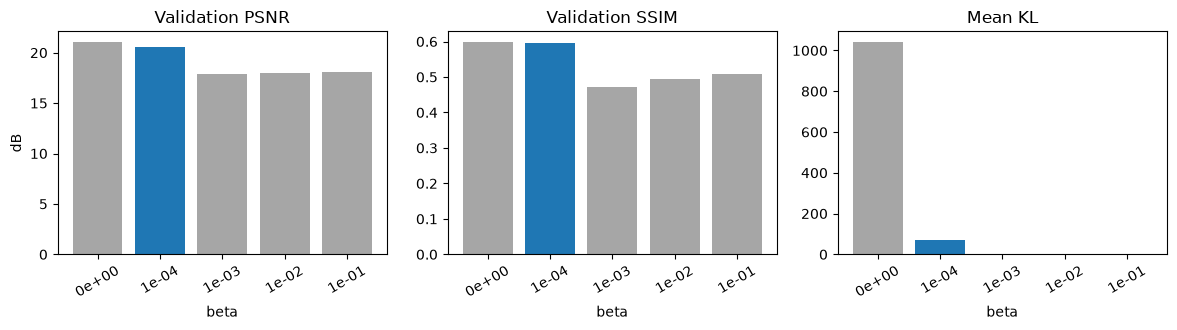

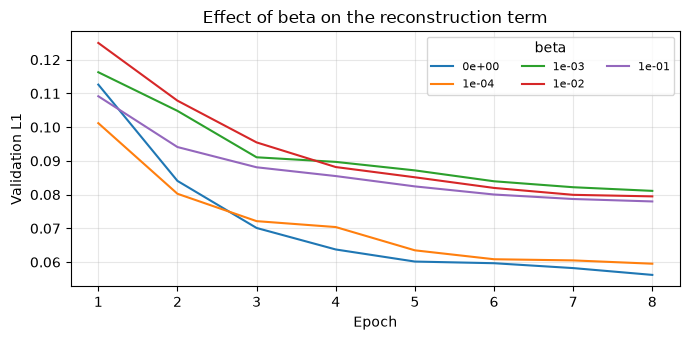

In [14]:
def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)

display(Markdown("### Validation scores after the short runs\n\n" + markdown_table(
    ["beta", "best epoch", "MAE", "PSNR (dB)", "SSIM", "KL", "minutes"],
    [[
        f"{row['beta']:.0e}", row["best_epoch"], f"{row['val_mae']:.4f}",
        f"{row['val_psnr']:.2f}", f"{row['val_ssim']:.3f}", f"{row['val_kl']:.2f}",
        f"{row['seconds'] / 60:.1f}",
    ] for row in ablation_rows],
)))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
labels = [f"{row['beta']:.0e}" for row in ablation_rows]
colors = ["0.65" if row["beta"] != SELECTED_BETA else "C0" for row in ablation_rows]
axes[0].bar(labels, [row["val_psnr"] for row in ablation_rows], color=colors)
axes[0].set_title("Validation PSNR")
axes[0].set_ylabel("dB")
axes[1].bar(labels, [row["val_ssim"] for row in ablation_rows], color=colors)
axes[1].set_title("Validation SSIM")
axes[2].bar(labels, [row["val_kl"] for row in ablation_rows], color=colors)
axes[2].set_title("Mean KL")
for ax in axes:
    ax.set_xlabel("beta")
    ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for beta, history in ablation_history.items():
    ax.plot(np.arange(1, len(history["val_recon"]) + 1), history["val_recon"], label=f"{beta:.0e}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation L1")
ax.set_title("Effect of beta on the reconstruction term")
ax.grid(True, alpha=0.3)
ax.legend(title="beta", ncol=3, fontsize=8)
fig.tight_layout()
plt.show()


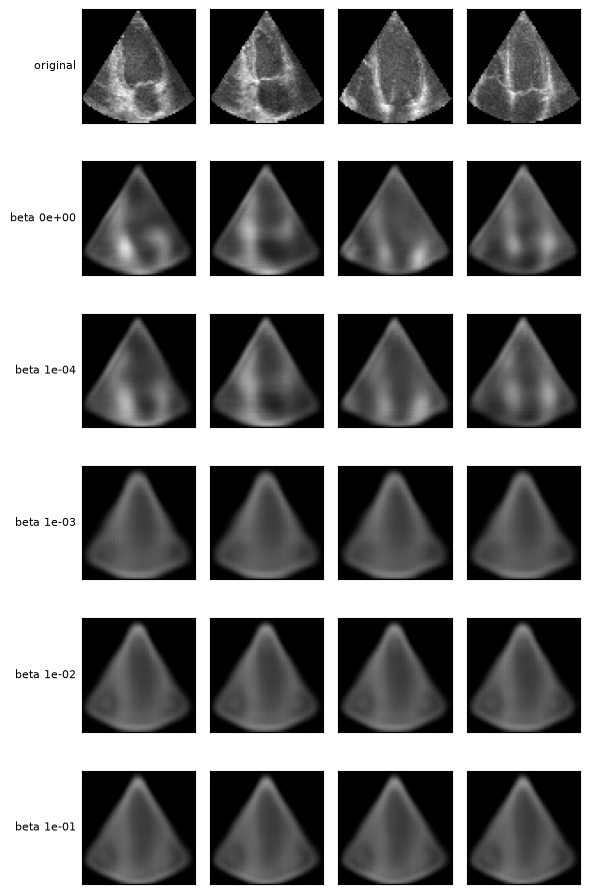

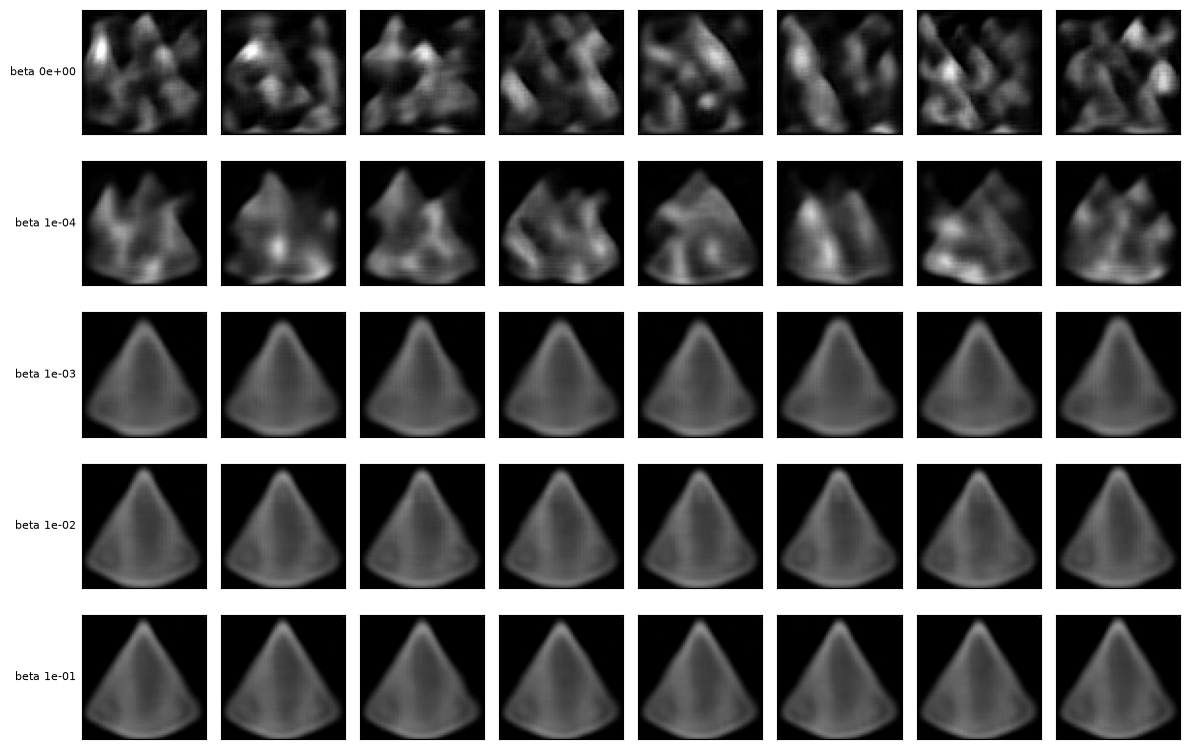

Top figure: same four validation frames. Bottom figure: the same eight draws from N(0, I).


In [15]:
fixed_images = torch.stack([valid_ds[i]["image"] for i in range(4)])
generator = torch.Generator(device="cpu")
generator.manual_seed(SEED)
prior_z = torch.randn((8, *LATENT_SHAPE), generator=generator)

def load_vae(tag):
    model = build_vae(SEED)
    model, history = load_checkpoint(model, tag)
    return model

recon_rows, sample_rows, row_titles = [], [], []
originals = fixed_images[:, 0].numpy()
for row in ablation_rows:
    model = load_vae(row["tag"])
    with torch.no_grad():
        recon, _, _, _ = forward_eval(model, fixed_images.to(device), "vae")
        samples = model.decode(prior_z.to(device))
    recon_rows.append(recon[:, 0].cpu().clamp(0, 1).numpy())
    sample_rows.append(samples[:, 0].cpu().clamp(0, 1).numpy())
    row_titles.append(f"beta {row['beta']:.0e}")
    del model

def show_grid(rows, titles, first_row=None, first_title=None):
    body = ([first_row] if first_row is not None else []) + rows
    names = ([first_title] if first_title is not None else []) + titles
    n_cols = body[0].shape[0]
    fig, axes = plt.subplots(len(body), n_cols, figsize=(1.5 * n_cols, 1.55 * len(body)))
    if len(body) == 1:
        axes = np.atleast_2d(axes)
    for i, row in enumerate(body):
        for j in range(n_cols):
            axes[i, j].imshow(row[j], cmap="gray", vmin=0, vmax=1)
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
        axes[i, 0].set_ylabel(names[i], rotation=0, ha="right", va="center", fontsize=8)
    fig.tight_layout()
    plt.show()

show_grid(recon_rows, row_titles, originals, "original")
show_grid(sample_rows, row_titles)
print("Top figure: same four validation frames. Bottom figure: the same eight draws from N(0, I).")


Reading the two figures together is the reconstruction-versus-regularization trade-off. A small β keeps valve detail and speckle, but draws from the prior fall off the ultrasound sector, because q(z|x) was never forced to occupy N(0, I). A large β makes prior samples look like sectors, and the reconstructions become smoother: the decoder only trusts codes that the prior can actually produce. The selected β is the strongest weight that stayed within 0.4 dB of the best positive-β validation PSNR. The long training run below uses that weight.


### Full training of the selected VAE, the deterministic autoencoder, and the VQ-VAE

The ablation models stay at the short budget so that the table above is a fair comparison. The model that is evaluated on the test set is trained for longer, from scratch, with a single cosine schedule. The autoencoder and the VQ-VAE receive their own full runs.


[vae_final] epoch 001/25  train 0.1526 (L1 0.1504, reg 111.706)  val 0.1039 (L1 0.1016)  beta 2.00e-05  lr 1.00e-03


[vae_final] epoch 002/25  train 0.0999 (L1 0.0956, reg 105.847)  val 0.0809 (L1 0.0759)  beta 4.00e-05  lr 9.96e-04


[vae_final] epoch 003/25  train 0.0940 (L1 0.0875, reg 109.515)  val 0.0814 (L1 0.0756)  beta 6.00e-05  lr 9.85e-04


[vae_final] epoch 004/25  train 0.0871 (L1 0.0797, reg 92.896)  val 0.0747 (L1 0.0675)  beta 8.00e-05  lr 9.67e-04


[vae_final] epoch 005/25  train 0.0833 (L1 0.0752, reg 80.454)  val 0.0752 (L1 0.0675)  beta 1.00e-04  lr 9.41e-04


[vae_final] epoch 006/25  train 0.0819 (L1 0.0746, reg 73.398)  val 0.0720 (L1 0.0648)  beta 1.00e-04  lr 9.09e-04


... (58 outputs left out)

[vqvae_final] epoch 018/20  train 0.0662 (L1 0.0509, reg 0.015)  val 0.0614 (L1 0.0484)  beta 0.00e+00  lr 1.02e-04


[vqvae_final] epoch 019/20  train 0.0657 (L1 0.0507, reg 0.015)  val 0.0624 (L1 0.0483)  beta 0.00e+00  lr 7.32e-05


[vqvae_final] epoch 020/20  train 0.0657 (L1 0.0506, reg 0.015)  val 0.0624 (L1 0.0483)  beta 0.00e+00  lr 5.58e-05


[vqvae_final] best epoch 18, 8.0 min, saved checkpoints/vqvae_final.pth


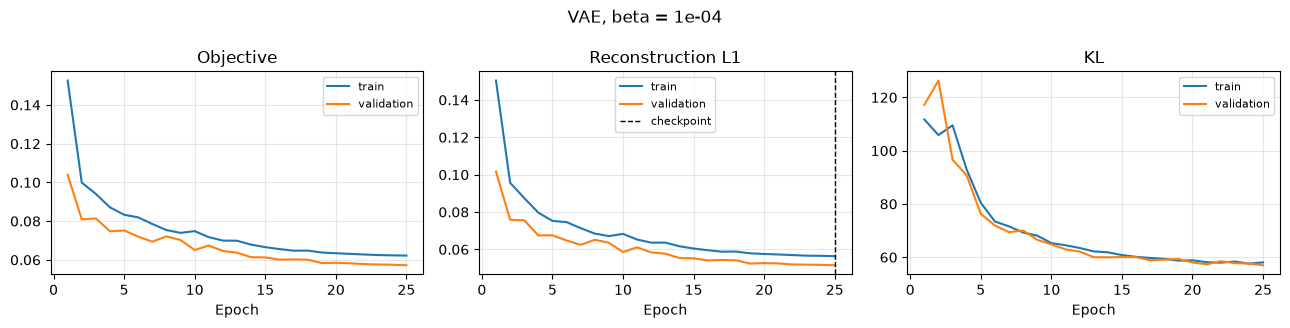

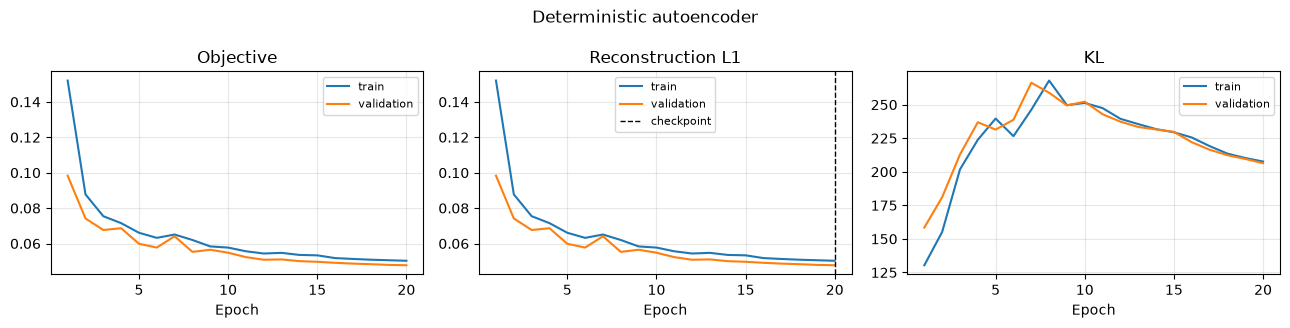

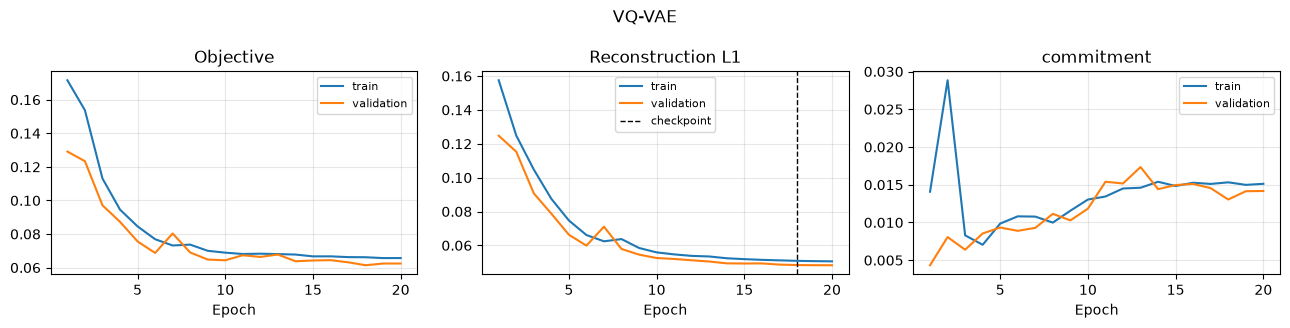

In [16]:
vae, vae_history = train_or_load(build_vae(SEED), "vae", FINAL_EPOCHS, SELECTED_BETA, tag="vae_final")
ae, ae_history = train_or_load(build_vae(SEED), "ae", AE_EPOCHS, 0.0, tag="ae_final")
vqvae, vq_history = train_or_load(build_vqvae(SEED), "vqvae", VQ_EPOCHS, 0.0, tag="vqvae_final")

def plot_history(history, title):
    epochs = np.arange(1, len(history["train_recon"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    axes[0].plot(epochs, history["train_total"], label="train")
    axes[0].plot(epochs, history["val_total"], label="validation")
    axes[0].set_title("Objective")
    axes[1].plot(epochs, history["train_recon"], label="train")
    axes[1].plot(epochs, history["val_recon"], label="validation")
    axes[1].axvline(history["best_epoch"], color="k", ls="--", lw=1, label="checkpoint")
    axes[1].set_title("Reconstruction L1")
    axes[2].plot(epochs, history["train_kl"], label="train")
    axes[2].plot(epochs, history["val_kl"], label="validation")
    axes[2].set_title(history["kl_name"])
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_history(vae_history, f"VAE, beta = {SELECTED_BETA:.0e}")
plot_history(ae_history, "Deterministic autoencoder")
plot_history(vq_history, "VQ-VAE")


The reconstruction term should fall and then flatten, with training and validation staying close. For the VAE, validation L1 sits slightly below training L1 because validation decodes the posterior mean, while each training step reconstructs a noisy sample. That offset is not overfitting. Overfitting would be a validation curve that rises while training keeps falling.

The KL starts high, because a random encoder is far from the standard normal, and training pulls it down toward a stable value. An unbounded KL would mean the posterior is running away from the prior. A KL stuck at zero would mean the code is ignored. The VQ-VAE commitment loss is a different quantity. It only needs to stay finite.

The checkpoint line is the epoch restored for evaluation. Because selection ignores the warm-up, that line is not the first epoch.


## Evaluate on the test patients

Metrics are computed on the 50 held-out patients. PSNR uses MONAI `PSNRMetric` with peak 1, on the raw decoder output, so values outside [0, 1] are penalized. SSIM uses MONAI `SSIMMetric` with a window of 7, after clamping to [0, 1], because the index assumes a known data range. MAE and MSE are the mean absolute and squared errors per frame.

The constant image equal to the mean training frame is a trivial baseline. A model that has only learned the sector shape will land close to it. Masks split the absolute error into the heart (labels 1, 2, and 3) and the background. The background is mostly black, so it is the easy part of the image.


In [17]:
def n_params(model):
    return sum(p.numel() for p in model.parameters())

def masked_mae(recon, image, label, inside):
    error = (recon - image).abs()
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()

def summarize_split(name, prediction):
    roi = masked_mae(prediction["recon"], prediction["image"], prediction["label"], inside=True)
    background = masked_mae(prediction["recon"], prediction["image"], prediction["label"], inside=False)
    summary_row = {
        "name": name,
        "mae": fmt_mean_std(prediction["mae"]),
        "mse": fmt_mean_std(prediction["mse"], digits=5),
        "psnr": fmt_mean_std(prediction["psnr"], digits=2),
        "ssim": fmt_mean_std(prediction["ssim"]),
        "roi_mae": fmt_mean_std(roi),
        "bg_mae": fmt_mean_std(background),
        "mae_mean": float(np.nanmean(prediction["mae"])),
        "psnr_mean": float(np.nanmean(prediction["psnr"])),
        "ssim_mean": float(np.nanmean(prediction["ssim"])),
        "roi_mean": float(np.nanmean(roi)),
        "bg_mean": float(np.nanmean(background)),
    }
    return summary_row, roi, background

vae_test = collect_predictions(vae, test_loader, "vae")
ae_test = collect_predictions(ae, test_loader, "ae")
vq_test = collect_predictions(vqvae, test_loader, "vqvae")
vae_val = collect_predictions(vae, valid_loader, "vae")

mean_frame = torch.stack([train_ds[i]["image"] for i in range(len(train_ds))]).mean(dim=0, keepdim=True)
mean_recon = mean_frame.expand(len(test_ds), -1, -1, -1).contiguous()
mean_test = {
    "image": vae_test["image"],
    "recon": mean_recon,
    "label": vae_test["label"],
    "view": vae_test["view"],
    "instant": vae_test["instant"],
    "quality": vae_test["quality"],
    "patient": vae_test["patient"],
    "ef": vae_test["ef"],
}
mae, mse, psnr, ssim = batch_scores(mean_test["recon"], mean_test["image"])
mean_test.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})

rows = []
detailed = {}
for name, prediction in (
    ("Mean frame", mean_test),
    ("Deterministic AE", ae_test),
    (f"VAE β={SELECTED_BETA:.0e}", vae_test),
    ("VQ-VAE", vq_test),
):
    summary_row, roi, background = summarize_split(name, prediction)
    rows.append(summary_row)
    detailed[name] = {"roi": roi, "background": background, "prediction": prediction}

display(Markdown("### Test reconstruction\n\n" + markdown_table(
    ["Model", "MAE", "MSE", "PSNR (dB)", "SSIM", "MAE on heart", "MAE on background"],
    [[row["name"], row["mae"], row["mse"], row["psnr"], row["ssim"], row["roi_mae"], row["bg_mae"]] for row in rows],
)))
val_psnr, _ = mean_std(vae_val["psnr"])
test_psnr, _ = mean_std(vae_test["psnr"])
print(f"VAE validation PSNR {val_psnr:.2f} dB, test PSNR {test_psnr:.2f} dB, gap {test_psnr - val_psnr:+.2f} dB")


### Test reconstruction

| Model | MAE | MSE | PSNR (dB) | SSIM | MAE on heart | MAE on background |
| --- | --- | --- | --- | --- | --- | --- |
| Mean frame | 0.082 ± 0.028 | 0.01970 ± 0.01562 | 17.75 ± 2.25 | 0.526 ± 0.072 | 0.132 ± 0.032 | 0.065 ± 0.030 |
| Deterministic AE | 0.052 ± 0.025 | 0.00863 ± 0.00970 | 21.77 ± 2.73 | 0.670 ± 0.064 | 0.081 ± 0.033 | 0.043 ± 0.022 |
| VAE β=1e-04 | 0.057 ± 0.026 | 0.01024 ± 0.01093 | 20.97 ± 2.68 | 0.622 ± 0.070 | 0.089 ± 0.034 | 0.046 ± 0.024 |
| VQ-VAE | 0.053 ± 0.018 | 0.00959 ± 0.00723 | 20.82 ± 2.15 | 0.597 ± 0.071 | 0.086 ± 0.018 | 0.042 ± 0.021 |

VAE validation PSNR 21.55 dB, test PSNR 20.97 dB, gap -0.58 dB


In [18]:
def group_table(prediction, key, metric="psnr"):
    groups = prediction[key]
    table_rows = []
    for group in sorted(set(groups)):
        selected = groups == group
        table_rows.append([group, int(selected.sum()), fmt_mean_std(prediction[metric][selected], digits=2)])
    return markdown_table([key, "n", "PSNR (dB)"], table_rows)

vae_name = f"VAE β={SELECTED_BETA:.0e}"
parts = ["### VAE test PSNR by acquisition\n"]
for key in ("view", "instant", "quality"):
    parts.append(group_table(vae_test, key))
    parts.append("")
display(Markdown("\n".join(parts)))


### VAE test PSNR by acquisition

| view | n | PSNR (dB) |
| --- | --- | --- |
| 2CH | 100 | 21.29 ± 2.82 |
| 4CH | 100 | 20.65 ± 2.48 |

| instant | n | PSNR (dB) |
| --- | --- | --- |
| ED | 100 | 20.87 ± 2.63 |
| ES | 100 | 21.06 ± 2.71 |

| quality | n | PSNR (dB) |
| --- | --- | --- |
| Good | 98 | 20.36 ± 2.85 |
| Medium | 86 | 21.65 ± 2.29 |
| Poor | 16 | 21.02 ± 2.59 |


/tmp/ipykernel_46462/3883720468.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


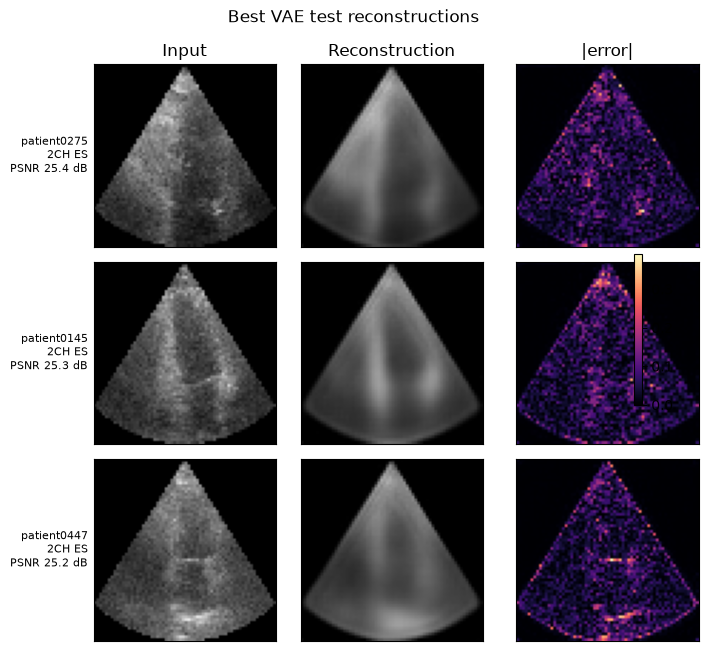

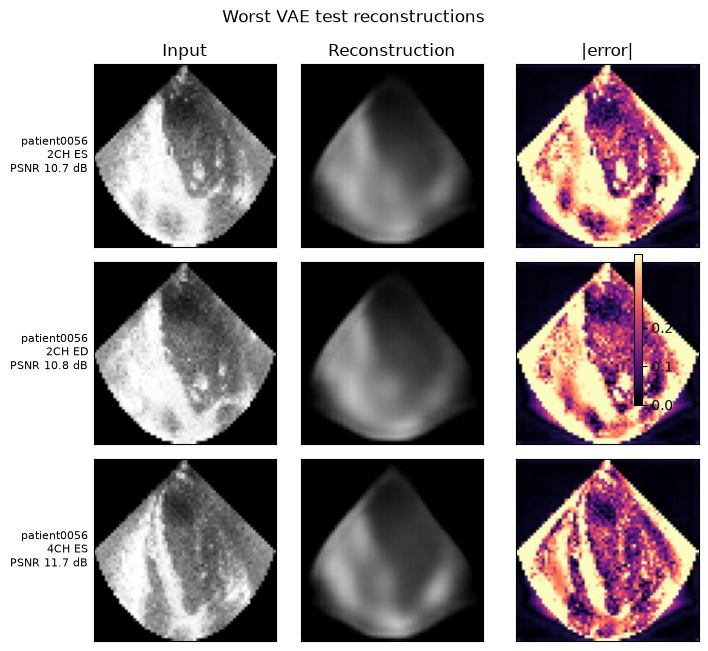

In [19]:
def error_panel(prediction, indexes, title):
    fig, axes = plt.subplots(len(indexes), 3, figsize=(7.2, 2.2 * len(indexes)))
    errors = (prediction["recon"] - prediction["image"]).abs().numpy()
    vmax = float(np.quantile(errors, 0.99))
    for row, index in enumerate(indexes):
        axes[row, 0].imshow(prediction["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        axes[row, 1].imshow(prediction["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
        im = axes[row, 2].imshow(errors[index, 0], cmap="magma", vmin=0, vmax=max(vmax, 1e-3))
        axes[row, 0].set_ylabel(
            f"{prediction['patient'][index]}\n{prediction['view'][index]} {prediction['instant'][index]}\n"
            f"PSNR {prediction['psnr'][index]:.1f} dB",
            rotation=0, ha="right", va="center", fontsize=8,
        )
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
    axes[0, 0].set_title("Input")
    axes[0, 1].set_title("Reconstruction")
    axes[0, 2].set_title("|error|")
    fig.colorbar(im, ax=axes[:, 2], fraction=0.046, pad=0.04)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

order = np.argsort(vae_test["psnr"])
error_panel(vae_test, order[-3:][::-1], "Best VAE test reconstructions")
error_panel(vae_test, order[:3], "Worst VAE test reconstructions")


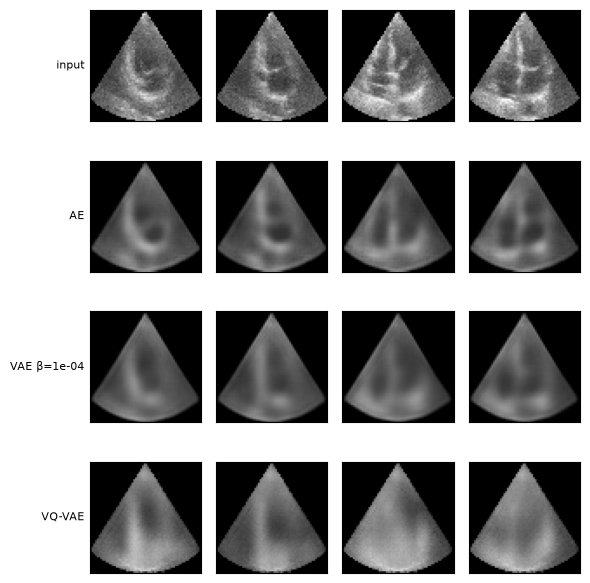

In [20]:
show_n = 4
comparison_rows = [
    vae_test["image"][:show_n, 0].numpy(),
    ae_test["recon"][:show_n, 0].clamp(0, 1).numpy(),
    vae_test["recon"][:show_n, 0].clamp(0, 1).numpy(),
    vq_test["recon"][:show_n, 0].clamp(0, 1).numpy(),
]
show_grid(comparison_rows[1:], ["AE", f"VAE β={SELECTED_BETA:.0e}", "VQ-VAE"], comparison_rows[0], "input")


The best frames are typical sectors with a clear cavity. The worst frames are the ones whose texture an 8×8 code cannot keep: sharp speckle, valves, and unusual windows. Image quality is not the same thing as reconstruction difficulty. A poor acoustic window can be darker and smoother, and therefore closer to a blurry reconstruction, so its PSNR can be higher than that of a sharp good-quality frame. The quality table is the measurement. Error maps still concentrate on the endocardial border, which is where the latent grid loses a one-pixel edge. Heart MAE above background MAE is the same fact over the whole test set: the background is black and easy.

Across views and instants, a large PSNR gap would mean the model only learned one acquisition. A gap of a few tenths of a decibel means the bottleneck is shared by 2-chamber and 4-chamber, ED and ES.


## Latent space

t-SNE reduces the 256-dimensional posterior mean of every test frame to two coordinates. It is a visualization, not a second model: distances are only local. The interesting question for echocardiography is whether the code organizes the acquisition (2-chamber versus 4-chamber, ED versus ES) and the clinical attributes available without using them as a loss: left-ventricular area and ejection fraction. That is the descriptive version of the attribute-regularized VAE from the lecture. Here the attributes are measured after training. They are not imposed on individual latent axes.


Latent matrix passed to t-SNE: (200, 256) = (test frames, 4×8×8).


t-SNE embedding: (200, 2)


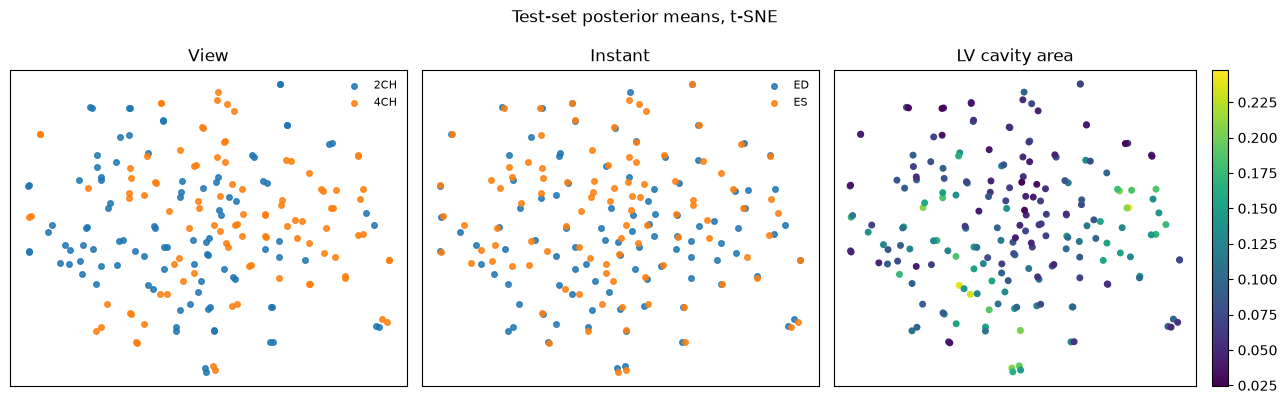

Pearson correlation of each latent channel (spatial mean) with a measured attribute:
  LV area             channels [+0.00, +0.09, -0.16, -0.05]  max |r| = 0.16
  myocardium area     channels [-0.11, -0.04, -0.03, +0.09]  max |r| = 0.11
  EF                  channels [-0.05, -0.02, +0.08, +0.02]  max |r| = 0.08


In [21]:
mu = vae_test["mu"].numpy()
flat = mu.reshape(mu.shape[0], -1)
print(f"Latent matrix passed to t-SNE: {flat.shape} = (test frames, 4×8×8).")
embedding = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(flat)
print(f"t-SNE embedding: {embedding.shape}")

lv_area = (vae_test["label"].numpy() == 1).mean(axis=(1, 2))
myo_area = (vae_test["label"].numpy() == 2).mean(axis=(1, 2))
channel_mean = mu.reshape(mu.shape[0], mu.shape[1], -1).mean(axis=2)

def pearson(left, right):
    mask = np.isfinite(left) & np.isfinite(right)
    if mask.sum() < 3 or np.std(left[mask]) == 0 or np.std(right[mask]) == 0:
        return float("nan")
    return float(np.corrcoef(left[mask], right[mask])[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, color, title, cmap in (
    (axes[0], vae_test["view"], "View", "tab10"),
    (axes[1], vae_test["instant"], "Instant", "coolwarm"),
):
    for class_id in sorted(set(color)):
        selected = color == class_id
        ax.scatter(embedding[selected, 0], embedding[selected, 1], s=16, alpha=0.85, label=str(class_id))
    ax.legend(frameon=False, fontsize=8)
    ax.set_title(title)
scatter = axes[2].scatter(embedding[:, 0], embedding[:, 1], c=lv_area, s=16, cmap="viridis")
axes[2].set_title("LV cavity area")
fig.colorbar(scatter, ax=axes[2], fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(True, color="0.9")
fig.suptitle("Test-set posterior means, t-SNE")
fig.tight_layout()
plt.show()

print("Pearson correlation of each latent channel (spatial mean) with a measured attribute:")
for name, attribute in (("LV area", lv_area), ("myocardium area", myo_area), ("EF", vae_test["ef"])):
    correlations = [pearson(channel_mean[:, channel], attribute) for channel in range(channel_mean.shape[1])]
    formatted = ", ".join(f"{value:+.2f}" for value in correlations)
    print(f"  {name:18s}  channels [{formatted}]  max |r| = {np.nanmax(np.abs(correlations)):.2f}")


The matrix passed to t-SNE has one row per test frame and 256 columns, the flattened posterior mean. t-SNE returns a 200×2 matrix, two coordinates per frame. It does not invent labels. Separation by view or by instant, if it appears, was learned from the images alone. Overlap is also informative: ED and ES of the same view are the same heart a few frames apart, so a code that clusters them together has kept identity rather than the cardiac phase.

A correlation of cavity area with one channel, even a moderate one, means geometry leaked into the Gaussian code without an attribute loss. The lecture's AR-VAE would reserve one axis per attribute and penalize disagreements inside the batch. That regularizer is the natural next step. It is not trained here, because the assignment is the reconstruction model and the attribute axes would need a second hyper-parameter search.


### Sampling the prior, and walking from ED to ES

Samples from N(0, I) test the completeness claim in the lecture. After a real KL term, those samples should land on ultrasound sectors. The deterministic autoencoder uses the same decoder family but never matched its codes to that prior, so the same noise should not look like a heart. The VQ-VAE is sampled by drawing codebook indices uniformly on the 8×8 grid. That is not a Gaussian draw. Uniform codes are often off the manifold of real encodings, which is a known limit of a VQ-VAE that has no autoregressive prior on the indices.


VQ-VAE codebook entries used by the test set: 2 / 128
VQ-VAE perplexity on the last test batch: 2.00


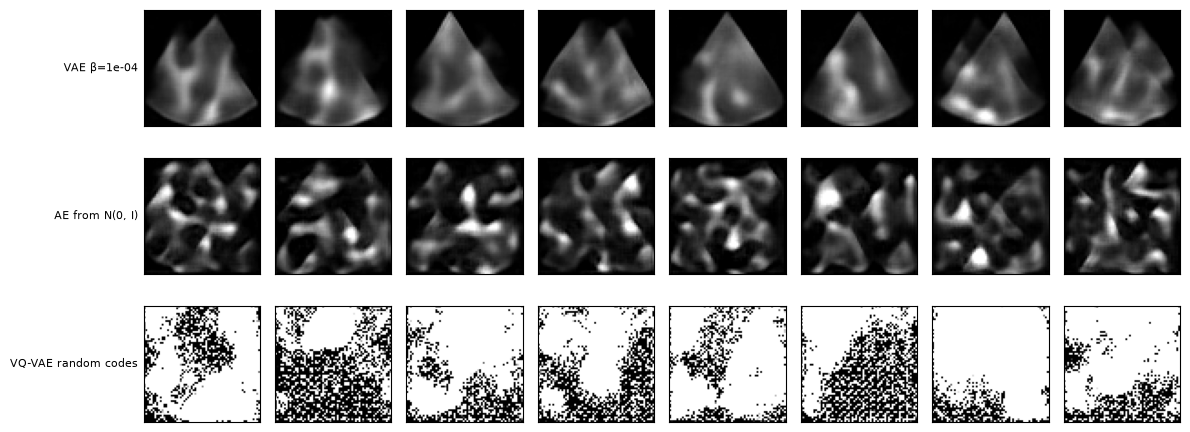

In [22]:
def decode_grid(model, z):
    with torch.no_grad():
        images = model.decode(z.to(device))
    return images[:, 0].cpu().clamp(0, 1).numpy()

vae_samples = decode_grid(vae, prior_z)
ae_samples = decode_grid(ae, prior_z)
with torch.no_grad():
    vq_indices = vqvae.index_quantize(test_ds[0]["image"][None].to(device))
    random_indices = torch.randint(0, vqvae.num_embeddings, (8, *tuple(vq_indices.shape[1:])), device=device)
    vq_samples = vqvae.decode_samples(random_indices)[:, 0].cpu().clamp(0, 1).numpy()
    used = []
    for batch in test_loader:
        used.append(vqvae.index_quantize(batch["image"].to(device)).detach().cpu().numpy().ravel())
    used = np.unique(np.concatenate(used))
print(f"VQ-VAE codebook entries used by the test set: {len(used)} / {vqvae.num_embeddings}")
print(f"VQ-VAE perplexity on the last test batch: {float(vqvae.quantizer.perplexity.detach()):.2f}")

show_grid(
    [vae_samples, ae_samples, vq_samples],
    [f"VAE β={SELECTED_BETA:.0e}", "AE from N(0, I)", "VQ-VAE random codes"],
)


Saved artifacts/interp_patient0010_4CH_ED_to_ES.gif (not included in the submission archive).


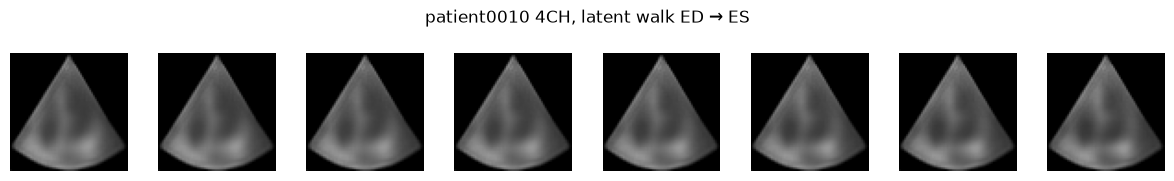

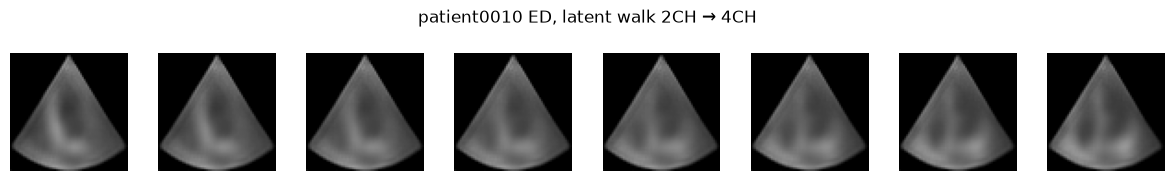

In [23]:
def pair_index(dataset):
    pairs = {}
    for index, record in enumerate(dataset.records):
        pairs.setdefault((record["patient"], record["view"]), {})[record["instant"]] = index
    return pairs

def encode_mu(model, dataset, index):
    image = dataset[index]["image"][None].to(device)
    with torch.no_grad():
        mu, _ = model.encode(image)
    return mu

def interpolate(model, z0, z1, steps):
    weights = torch.linspace(0, 1, steps, device=z0.device)
    codes = torch.cat([torch.lerp(z0, z1, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = model.decode(codes)[:, 0].cpu().clamp(0, 1).numpy()
    return frames

def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)

pairs = pair_index(test_ds)
ed_es = next(
    (indexes["ED"], indexes["ES"], patient, view)
    for (patient, view), indexes in pairs.items()
    if "ED" in indexes and "ES" in indexes and view == "4CH"
)
cross = next(
    patient for (patient, view), indexes in pairs.items()
    if view == "2CH" and "ED" in indexes and (patient, "4CH") in pairs and "ED" in pairs[(patient, "4CH")]
)

z_ed = encode_mu(vae, test_ds, ed_es[0])
z_es = encode_mu(vae, test_ds, ed_es[1])
cycle = interpolate(vae, z_ed, z_es, steps=16)
gif_path = ARTIFACT_DIR / f"interp_{ed_es[2]}_4CH_ED_to_ES.gif"
save_gif(cycle, gif_path)
print(f"Saved {gif_path} (not included in the submission archive).")

z_2ch = encode_mu(vae, test_ds, pairs[(cross, "2CH")]["ED"])
z_4ch = encode_mu(vae, test_ds, pairs[(cross, "4CH")]["ED"])
view_walk = interpolate(vae, z_2ch, z_4ch, steps=8)

def strip(frames, title, step=1):
    shown = frames[::step]
    fig, axes = plt.subplots(1, len(shown), figsize=(1.5 * len(shown), 1.8))
    for ax, frame in zip(axes, shown):
        ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

strip(cycle, f"{ed_es[2]} 4CH, latent walk ED → ES", step=2)
strip(view_walk, f"{cross} ED, latent walk 2CH → 4CH", step=1)


A smooth ED-to-ES walk means the posterior means of the two instants are neighbors and the decoder does not jump through a nonsense image in between. That is the continuity property from the lecture, checked on a pair that is physiologically ordered: the cavity should shrink rather than morph into a different patient. The 2-chamber to 4-chamber walk is a harder demand, because the two views are different slices. A plausible intermediate is a good sign. An intermediate that breaks the sector is equally informative: the linear path left the region the decoder knows.

The GIF is written under `artifacts/` for local inspection. The strip above is the result stored in the notebook.


## Comparison and conclusion


In [24]:
def model_row(name, params, history, prediction):
    return [
        name,
        f"{params:,}",
        history["epochs"] if history else "—",
        f"{history['seconds'] / 60:.1f}" if history else "—",
        fmt_mean_std(prediction["mae"]),
        fmt_mean_std(prediction["psnr"], digits=2),
        fmt_mean_std(prediction["ssim"]),
    ]

comparison = [
    model_row("Mean training frame", 0, None, mean_test),
    model_row("Deterministic AE", n_params(ae), ae_history, ae_test),
    model_row(f"VAE β={SELECTED_BETA:.0e}", n_params(vae), vae_history, vae_test),
    model_row("VQ-VAE", n_params(vqvae), vq_history, vq_test),
]
display(Markdown(markdown_table(
    ["Model", "Parameters", "Epochs", "Minutes", "Test MAE", "Test PSNR (dB)", "Test SSIM"],
    comparison,
)))

vae_row = next(row for row in rows if row["name"].startswith("VAE"))
ae_row = next(row for row in rows if row["name"].startswith("Deterministic"))
vq_row = next(row for row in rows if row["name"].startswith("VQ"))
base_row = rows[0]
betas = np.array([row["beta"] for row in ablation_rows], dtype=np.float64)
psnrs = np.array([row["val_psnr"] for row in ablation_rows])
order_beta = np.argsort(betas)
ordered_psnr = psnrs[order_beta]
psnr_drop = float(ordered_psnr[0] - ordered_psnr[-1])
mostly_decreasing = psnr_drop >= 0.4 and bool(np.all(np.diff(ordered_psnr) <= 0.15))
channel_lv = [abs(pearson(channel_mean[:, channel], lv_area)) for channel in range(channel_mean.shape[1])]

paragraphs = []
paragraphs.append(
    f"The KL weight retained for the VAE is {SELECTED_BETA:.0e}. "
    f"It is the strongest positive weight whose short-run validation PSNR stayed within 0.4 dB of the best positive weight."
)
if mostly_decreasing:
    paragraphs.append(
        "On the short runs, validation PSNR falls as beta grows. "
        "That is the expected exchange between the data term and the KL term."
    )
else:
    paragraphs.append(
        "On the short runs, validation PSNR does not fall monotonically with beta. "
        "With only a few epochs the ranking is still noisy, which is why the long VAE run is the one reported on the test set, and why the 0.4 dB band rejects a weight only when the loss is clear."
    )
paragraphs.append(
    f"On the test patients the VAE reaches {vae_row['psnr_mean']:.2f} dB PSNR and SSIM {vae_row['ssim_mean']:.3f}. "
    f"The mean-frame baseline is at {base_row['psnr_mean']:.2f} dB. "
    f"The deterministic autoencoder reaches {ae_row['psnr_mean']:.2f} dB and the VQ-VAE {vq_row['psnr_mean']:.2f} dB."
)
if vae_row["psnr_mean"] > base_row["psnr_mean"] + 1:
    paragraphs.append("The VAE is well above the mean frame, so the decoder is not just painting the average sector.")
else:
    paragraphs.append("The VAE does not clearly beat the mean frame, so part of the score is still the average sector rather than patient-specific anatomy.")
if ae_row["psnr_mean"] + 0.05 >= vae_row["psnr_mean"]:
    paragraphs.append(
        "The deterministic autoencoder reconstructs at least as well as the VAE. "
        "Removing the KL term and the sampling noise frees capacity for the data term. "
        "The VAE pays that cost so its codes stay close to the standard normal prior. "
        "The sampling figure is the check that this actually puts new images on the ultrasound manifold."
    )
else:
    paragraphs.append(
        "The VAE matches or exceeds the deterministic autoencoder on test PSNR. "
        "The KL term did not have to destroy reconstruction at the selected weight."
    )
paragraphs.append(
    f"Validation and test PSNR of the VAE differ by {test_psnr - val_psnr:+.2f} dB. "
    + ("The patient-wise split does not show overfitting." if abs(test_psnr - val_psnr) < 1 else
       "The gap is large enough that the validation patients were an easier or harder set than the test patients. The checkpoint was still chosen on validation only.")
)
paragraphs.append(
    f"Mean absolute error is {vae_row['roi_mean']:.4f} inside the expert heart mask and {vae_row['bg_mean']:.4f} on the background. "
    "The background is mostly zero and dominates the pixel count, so full-image PSNR flatters a model that blurs the cavity."
)
paragraphs.append(
    f"The strongest absolute Pearson correlation between a latent channel and left-ventricular area is {max(channel_lv):.2f}. "
    "Geometry is only partly aligned with single channels. An attribute-regularized VAE would be the way to force one axis per measurement."
)
paragraphs.append(
    f"The VQ-VAE uses {len(used)} of {vqvae.num_embeddings} codebook entries on the test set."
)
if len(used) < 0.1 * vqvae.num_embeddings:
    paragraphs.append(
        "Most codebook entries are unused, so drawing indices uniformly is not a sample from the data distribution. "
        "A discrete model needs a prior on the indices before those draws are meaningful."
    )
display(Markdown("\n\n".join(paragraphs)))

results = {
    "selected_beta": SELECTED_BETA,
    "ablation": ablation_rows,
    "test": [{key: row[key] for key in ("name", "mae", "mse", "psnr", "ssim", "roi_mae", "bg_mae")} for row in rows],
    "vae_val_psnr": val_psnr,
    "vae_test_psnr": test_psnr,
    "latent_shape": list(LATENT_SHAPE),
    "vq_codes_used": int(len(used)),
    "vq_codes": int(vqvae.num_embeddings),
}
ARTIFACT_DIR.mkdir(exist_ok=True)
(ARTIFACT_DIR / "results.json").write_text(json.dumps(results, indent=2))
print(f"Wrote {ARTIFACT_DIR / 'results.json'}")


| Model | Parameters | Epochs | Minutes | Test MAE | Test PSNR (dB) | Test SSIM |
| --- | --- | --- | --- | --- | --- | --- |
| Mean training frame | 0 | — | — | 0.082 ± 0.028 | 17.75 ± 2.25 | 0.526 ± 0.072 |
| Deterministic AE | 473,649 | 20 | 22.0 | 0.052 ± 0.025 | 21.77 ± 2.73 | 0.670 ± 0.064 |
| VAE β=1e-04 | 473,649 | 25 | 26.8 | 0.057 ± 0.026 | 20.97 ± 2.68 | 0.622 ± 0.070 |
| VQ-VAE | 571,361 | 20 | 8.0 | 0.053 ± 0.018 | 20.82 ± 2.15 | 0.597 ± 0.071 |

The KL weight retained for the VAE is 1e-04. It is the strongest positive weight whose short-run validation PSNR stayed within 0.4 dB of the best positive weight.

On the short runs, validation PSNR falls as beta grows. That is the expected exchange between the data term and the KL term.

On the test patients the VAE reaches 20.97 dB PSNR and SSIM 0.622. The mean-frame baseline is at 17.75 dB. The deterministic autoencoder reaches 21.77 dB and the VQ-VAE 20.82 dB.

The VAE is well above the mean frame, so the decoder is not just painting the average sector.

The deterministic autoencoder reconstructs at least as well as the VAE. Removing the KL term and the sampling noise frees capacity for the data term. The VAE pays that cost so its codes stay close to the standard normal prior. The sampling figure is the check that this actually puts new images on the ultrasound manifold.

Validation and test PSNR of the VAE differ by -0.58 dB. The patient-wise split does not show overfitting.

Mean absolute error is 0.0895 inside the expert heart mask and 0.0456 on the background. The background is mostly zero and dominates the pixel count, so full-image PSNR flatters a model that blurs the cavity.

The strongest absolute Pearson correlation between a latent channel and left-ventricular area is 0.16. Geometry is only partly aligned with single channels. An attribute-regularized VAE would be the way to force one axis per measurement.

The VQ-VAE uses 2 of 128 codebook entries on the test set.

Most codebook entries are unused, so drawing indices uniformly is not a sample from the data distribution. A discrete model needs a prior on the indices before those draws are meaningful.

Wrote artifacts/results.json


### What limits these numbers

The images are 64×64, and the code is 8×8. Edges of the endocardium are a pixel or two wide, so an L1 decoder prefers a smooth border. That blur is also what the Gaussian (or Laplacian) likelihood in the lecture predicts: the decoder outputs a conditional mean, and speckle is zero-mean texture, so it is averaged away. A perceptual or adversarial term would buy sharpness and would need its own weight, on top of β.

Training is a single seed on CPU. The epoch budget is large enough for the validation curve to flatten on this width, and too small to claim that a wider attentive network would not do better on a GPU. The architecture section gives the timing that motivated the width. The latent grid was not reduced to make training faster.

Only ED and ES are used, not the frames in between, so the latent walk is a test of interpolation rather than a model of the cardiac cycle. Temporal consistency of the kind discussed for segmentation post-processing is out of scope: there is no segmentation head.

The VQ-VAE codebook is a second generative model only if the indices themselves are modeled. Uniform index noise is reported so that its samples are not confused with the Gaussian samples of the VAE.

### A next model, not trained here

The lecture's attribute-regularized VAE would add, inside each batch, a penalty between distances of a measured attribute and distances along one latent coordinate. Cavity area, cavity length, and myocardial area are the natural CAMUS attributes, and the masks already provide them. The correlations above are the unsupervised trace of that structure. Training the penalty would be a second project: it does not change the reconstruction metrics that this assignment asks for, and it adds a weight that has to be calibrated against β.

### Citation

S. Leclerc, E. Smistad, J. Pedrosa, A. Ostvik, et al. "Deep Learning for Segmentation using an Open Large-Scale Dataset in 2D Echocardiography". IEEE Transactions on Medical Imaging, vol. 38, no. 9, pp. 2198-2210, Sept. 2019. doi: 10.1109/TMI.2019.2900516.
